In [1]:

# ==========================================
# FAIRXAI — STAGE 6
# Balanced Model Development
# ==========================================

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Data splitting and validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("FairXAI Stage 6 environment initialized successfully.")
print("Random State:", RANDOM_STATE)


FairXAI Stage 6 environment initialized successfully.
Random State: 42


In [2]:

# ==========================================
# STEP 2 — LOAD ORIGINAL DATASET
# ==========================================

dataset_path = r"D:\TY_Sem1\MLOps\FairXAi\data\raw\taiwan_credit_default_original.xls"

df = pd.read_excel(dataset_path, header=1)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Dataset loaded successfully.
Dataset shape: (30000, 25)

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

First five rows:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:

# ==========================================
# STEP 3 — DATA QUALITY AUDIT
# ==========================================

target = "default payment next month"

print("DATASET QUALITY")
print("----------------")
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())

print("\nMissing values by column:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nData types:")
display(df.dtypes.value_counts())

print("\nTarget distribution:")
display(df[target].value_counts().sort_index())

print("\nTarget distribution (%):")
display(
    (df[target].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nUnique target values:")
print(sorted(df[target].dropna().unique()))


DATASET QUALITY
----------------
Missing values: 0
Duplicate rows: 0
Duplicate IDs: 0

Missing values by column:


Series([], dtype: int64)


Data types:


int64    25
Name: count, dtype: int64


Target distribution:


default payment next month
0    23364
1     6636
Name: count, dtype: int64


Target distribution (%):


default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


Unique target values:
[np.int64(0), np.int64(1)]


In [4]:
# ==========================================
# STEP 4 — DEFINE FEATURES AND TARGET
# ==========================================

target = "default payment next month"

# Protected attributes for later fairness evaluation
protected_columns = [
    "SEX",
    "AGE",
    "EDUCATION",
    "MARRIAGE"
]

# Remove ID and target from predictive features
X = df.drop(columns=["ID", target]).copy()
y = df[target].copy()

# Keep a separate copy of sensitive attributes
sensitive = X[protected_columns].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Sensitive attributes shape:", sensitive.shape)

print("\nPredictive features:")
print(X.columns.tolist())

print("\nProtected attributes:")
print(protected_columns)

print("\nTarget classes:")
print(y.value_counts().to_dict())

Feature matrix shape: (30000, 23)
Target shape: (30000,)
Sensitive attributes shape: (30000, 4)

Predictive features:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

Protected attributes:
['SEX', 'AGE', 'EDUCATION', 'MARRIAGE']

Target classes:
{0: 23364, 1: 6636}


In [5]:
# ==========================================
# STEP 5 — STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ==========================================

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

# Keep protected attributes aligned with each split
sensitive_train = sensitive.loc[X_train.index]
sensitive_val = sensitive.loc[X_val.index]
sensitive_test = sensitive.loc[X_test.index]

print("DATASET SPLIT")
print("-------------")

for name, X_part, y_part in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:
    print(f"\n{name}:")
    print("Features:", X_part.shape)
    print("Target:", y_part.shape)
    print("Class distribution (%):")
    print((y_part.value_counts(normalize=True).sort_index() * 100).round(2))

DATASET SPLIT
-------------

Training:
Features: (21000, 23)
Target: (21000,)
Class distribution (%):
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

Validation:
Features: (4500, 23)
Target: (4500,)
Class distribution (%):
default payment next month
0    77.89
1    22.11
Name: proportion, dtype: float64

Testing:
Features: (4500, 23)
Target: (4500,)
Class distribution (%):
default payment next month
0    77.87
1    22.13
Name: proportion, dtype: float64


In [10]:
# ==========================================
# STEP 6 — UPDATED PREPROCESSING PIPELINE
# ==========================================

categorical_features = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

numerical_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

print("Updated preprocessing pipeline created.")
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Output format: Dense")

Updated preprocessing pipeline created.
Numerical features: 14
Categorical features: 9
Output format: Dense


In [11]:
# ==========================================
# STEP 7 — DEFINE THE SEVEN MODELS
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Class imbalance ratio from training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "SVM": SVC(
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Seven models defined successfully.")
print(f"Training class imbalance ratio: {scale_pos_weight:.3f}")

for model_name in models:
    print("-", model_name)

Seven models defined successfully.
Training class imbalance ratio: 3.521
- Logistic Regression
- KNN
- Gaussian Naive Bayes
- SVM
- Decision Tree
- Random Forest
- XGBoost


In [12]:
# ==========================================
# STEP 8 — BUILD MODEL PIPELINES
# ==========================================

model_pipelines = {}

for model_name, model in models.items():
    model_pipelines[model_name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

print("Pipelines created successfully.")
print("Number of model pipelines:", len(model_pipelines))

for model_name in model_pipelines:
    print("-", model_name)

Pipelines created successfully.
Number of model pipelines: 7
- Logistic Regression
- KNN
- Gaussian Naive Bayes
- SVM
- Decision Tree
- Random Forest
- XGBoost


In [13]:
# ==========================================
# STEP 9 — TRAIN AND EVALUATE SEVEN MODELS
# ==========================================

baseline_results = []
trained_models = {}

for model_name, pipeline in model_pipelines.items():

    print(f"Training {model_name}...")

    pipeline.fit(X_train, y_train)

    # Validation predictions
    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    baseline_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall (Defaulters)": recall_score(y_val, y_pred, zero_division=0),
        "Specificity (Non-defaulters)": tn / (tn + fp),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC": average_precision_score(y_val, y_prob),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    trained_models[model_name] = pipeline

baseline_results_df = pd.DataFrame(baseline_results)

print("\nBASELINE VALIDATION RESULTS — THRESHOLD 0.5")
display(
    baseline_results_df
    .sort_values("Balanced Accuracy", ascending=False)
    .round(4)
)

Training Logistic Regression...
Training KNN...
Training Gaussian Naive Bayes...
Training SVM...


D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Training Decision Tree...
Training Random Forest...
Training XGBoost...

BASELINE VALIDATION RESULTS — THRESHOLD 0.5


,Model,Accuracy,Precision,Recall (Defaulters),Specificity (Non-defaulters),F1,Balanced Accuracy,ROC-AUC,PR-AUC,TN,FP,FN,TP
3,SVM,0.7787,0.4996,0.5598,0.8408,0.5280,0.7003,0.7587,0.4919,2947,558,438,557
0,Logistic Regression,0.7753,0.4929,0.5548,0.8379,0.5220,0.6964,0.7668,0.5227,2937,568,443,552
6,XGBoost,0.7578,0.4610,0.5638,0.8128,0.5072,0.6883,0.7520,0.5234,2849,656,434,561
5,Random Forest,0.8024,0.5622,0.4814,0.8936,0.5187,0.6875,0.7607,0.5285,3132,373,516,479
1,KNN,0.7969,0.5692,0.3347,0.9281,0.4215,0.6314,0.7052,0.4167,3253,252,662,333
4,Decision Tree,0.7307,0.3912,0.3920,0.8268,0.3916,0.6094,0.6094,0.2878,2898,607,605,390
2,Gaussian Naive Bayes,0.7902,0.6349,0.1206,0.9803,0.2027,0.5505,0.7236,0.4762,3436,69,875,120


In [14]:
# ==========================================
# STEP 10 — VALIDATION THRESHOLD ANALYSIS
# ==========================================

threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.01)

for model_name, pipeline in trained_models.items():

    y_prob = pipeline.predict_proba(X_val)[:, 1]

    best_threshold = None
    best_balanced_accuracy = -1

    for threshold in thresholds:

        y_pred_threshold = (y_prob >= threshold).astype(int)

        score = balanced_accuracy_score(
            y_val,
            y_pred_threshold
        )

        if score > best_balanced_accuracy:
            best_balanced_accuracy = score
            best_threshold = threshold

    # Evaluate at the selected threshold
    y_pred_best = (y_prob >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred_best, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Model": model_name,
        "Best Threshold": best_threshold,
        "Balanced Accuracy": best_balanced_accuracy,
        "Precision": precision_score(y_val, y_pred_best, zero_division=0),
        "Recall (Defaulters)": recall_score(y_val, y_pred_best, zero_division=0),
        "Specificity (Non-defaulters)": tn / (tn + fp),
        "F1": f1_score(y_val, y_pred_best, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_results_df = pd.DataFrame(threshold_results)

print("VALIDATION RESULTS AFTER THRESHOLD SELECTION")
display(
    threshold_results_df
    .sort_values("Balanced Accuracy", ascending=False)
    .round(4)
)

VALIDATION RESULTS AFTER THRESHOLD SELECTION


,Model,Best Threshold,Balanced Accuracy,Precision,Recall (Defaulters),Specificity (Non-defaulters),F1,TN,FP,FN,TP
5,Random Forest,0.37,0.7025,0.4594,0.6080,0.7969,0.5234,2793,712,390,605
3,SVM,0.19,0.7018,0.4514,0.6161,0.7874,0.5210,2760,745,382,613
0,Logistic Regression,0.48,0.7008,0.4820,0.5779,0.8237,0.5256,2887,618,420,575
6,XGBoost,0.47,0.6892,0.4426,0.5889,0.7894,0.5054,2767,738,409,586
1,KNN,0.21,0.6661,0.4283,0.5347,0.7974,0.4756,2795,710,463,532
4,Decision Tree,0.10,0.6094,0.3912,0.3920,0.8268,0.3916,2898,607,605,390
2,Gaussian Naive Bayes,0.11,0.5711,0.6653,0.1658,0.9763,0.2655,3422,83,830,165


In [16]:
# ==========================================
# STEP 11 — HYPERPARAMETER TUNING: ALL 7 MODELS
# ==========================================

from sklearn.base import clone

# Faster stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Compact, model-specific parameter grids
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10]
    },

    "KNN": {
        "classifier__n_neighbors": [5, 11, 21],
        "classifier__weights": ["uniform", "distance"]
    },

    "Gaussian Naive Bayes": {
        "classifier__var_smoothing": [1e-9, 1e-8, 1e-7]
    },

    "SVM": {
        "classifier__C": [0.1, 1, 10]
    },

    "Decision Tree": {
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 5]
    },

    "Random Forest": {
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 5]
    },

    "XGBoost": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [3, 5],
        "classifier__learning_rate": [0.05, 0.1]
    }
}

tuned_models = {}
tuning_results = []

for model_name, param_grid in param_grids.items():

    print(f"\nTuning {model_name}...")

    estimator = clone(model_pipelines[model_name])

    # SVM decision scores are sufficient for ROC-AUC tuning.
    # This avoids expensive probability estimation during CV.
    if model_name == "SVM":
        estimator.set_params(classifier__probability=False)

    grid_search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    tuned_models[model_name] = grid_search.best_estimator_

    tuning_results.append({
        "Model": model_name,
        "Best CV ROC-AUC": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_results)

print("\nALL SEVEN MODELS — TUNING RESULTS")

display(
    tuning_results_df
    .sort_values("Best CV ROC-AUC", ascending=False)
    .round(4)
)


Tuning Logistic Regression...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Tuning KNN...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Tuning Gaussian Naive Bayes...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Tuning SVM...
Fitting 3 folds for each of 3 candidates, totalling 9 fits


D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Tuning Decision Tree...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Tuning Random Forest...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Tuning XGBoost...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

ALL SEVEN MODELS — TUNING RESULTS


,Model,Best CV ROC-AUC,Best Parameters
6,XGBoost,0.7824,"{'classifier__learning_rate': 0.1, 'classifier..."
5,Random Forest,0.7810,"{'classifier__max_depth': 20, 'classifier__min..."
0,Logistic Regression,0.7706,{'classifier__C': 0.1}
3,SVM,0.7664,{'classifier__C': 0.1}
2,Gaussian Naive Bayes,0.7415,{'classifier__var_smoothing': 1e-09}
1,KNN,0.7327,"{'classifier__n_neighbors': 21, 'classifier__w..."
4,Decision Tree,0.7260,"{'classifier__max_depth': 10, 'classifier__min..."


In [17]:
# ==========================================
# STEP 12 — VALIDATION OF ALL TUNED MODELS
# ==========================================

from sklearn.metrics import roc_curve

tuned_validation_results = []
tuned_validation_scores = {}

for model_name, model in tuned_models.items():

    print(f"Evaluating {model_name}...")

    # Obtain model scores
    if model_name == "SVM":
        scores = model.decision_function(X_val)
    else:
        scores = model.predict_proba(X_val)[:, 1]

    tuned_validation_scores[model_name] = scores

    # Find threshold maximizing balanced accuracy
    fpr, tpr, thresholds = roc_curve(y_val, scores)

    balanced_accuracies = (tpr + 1 - fpr) / 2
    best_index = np.argmax(balanced_accuracies)

    best_threshold = thresholds[best_index]

    y_pred = (scores >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    tuned_validation_results.append({
        "Model": model_name,
        "Threshold": best_threshold,
        "Balanced Accuracy": balanced_accuracies[best_index],
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall (Defaulters)": recall_score(y_val, y_pred, zero_division=0),
        "Specificity (Non-defaulters)": tn / (tn + fp),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, scores),
        "PR-AUC": average_precision_score(y_val, scores),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

tuned_validation_df = pd.DataFrame(tuned_validation_results)

print("\nTUNED MODEL VALIDATION RESULTS")

display(
    tuned_validation_df
    .sort_values("Balanced Accuracy", ascending=False)
    .round(4)
)

Evaluating Logistic Regression...
Evaluating KNN...
Evaluating Gaussian Naive Bayes...
Evaluating SVM...
Evaluating Decision Tree...
Evaluating Random Forest...
Evaluating XGBoost...

TUNED MODEL VALIDATION RESULTS


,Model,Threshold,Balanced Accuracy,Accuracy,Precision,Recall (Defaulters),Specificity (Non-defaulters),F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
6,XGBoost,0.5027,0.7128,0.7633,0.4732,0.6221,0.8034,0.5376,0.7789,0.5535,2816,689,376,619
5,Random Forest,0.5057,0.7109,0.7862,0.5148,0.5759,0.8459,0.5436,0.7763,0.5514,2965,540,422,573
0,Logistic Regression,0.4296,0.7002,0.7236,0.4201,0.6583,0.7421,0.5129,0.7674,0.5252,2601,904,340,655
3,SVM,-0.3952,0.6978,0.7584,0.4636,0.5889,0.8066,0.5188,0.7612,0.5077,2827,678,409,586
2,Gaussian Naive Bayes,0.0000,0.6876,0.7504,0.4497,0.5749,0.8003,0.5046,0.7236,0.4762,2805,700,423,572
4,Decision Tree,0.3698,0.6827,0.6604,0.3648,0.7226,0.6428,0.4848,0.7403,0.4748,2253,1252,276,719
1,KNN,0.2381,0.6812,0.7209,0.4115,0.6101,0.7524,0.4915,0.7446,0.4962,2637,868,388,607


In [18]:
# Select the two leading models based on validation results

selected_models = ["XGBoost", "Random Forest"]

selected_thresholds = (
    tuned_validation_df
    .set_index("Model")
    .loc[selected_models, "Threshold"]
    .to_dict()
)

final_candidates = {
    name: tuned_models[name]
    for name in selected_models
}

print("Selected candidates:")
for name in selected_models:
    print(f"{name}: threshold = {selected_thresholds[name]:.4f}")

Selected candidates:
XGBoost: threshold = 0.5027
Random Forest: threshold = 0.5057


In [19]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    roc_auc_score, average_precision_score,
    confusion_matrix
)

final_test_results = []

for model_name, model in final_candidates.items():

    # Generate test scores
    if model_name == "SVM":
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]

    # Apply the threshold selected using validation data
    threshold = selected_thresholds[model_name]
    y_pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    final_test_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall (Defaulters)": recall_score(y_test, y_pred, zero_division=0),
        "Specificity (Non-defaulters)": tn / (tn + fp),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "PR-AUC": average_precision_score(y_test, scores),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

final_test_df = pd.DataFrame(final_test_results)

display(final_test_df.round(4))

,Model,Threshold,Accuracy,Precision,Recall (Defaulters),Specificity (Non-defaulters),F1,Balanced Accuracy,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,XGBoost,0.5027,0.7636,0.4744,0.6325,0.8008,0.5422,0.7167,0.7799,0.5574,2806,698,366,630
1,Random Forest,0.5057,0.7844,0.5113,0.5894,0.8399,0.5476,0.7146,0.7805,0.5546,2943,561,409,587


In [21]:
%pip install shap lime

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/554.9 kB ? eta -:--:--
   ---------------------------------------- 554.9/554.9 kB 3.1 MB/s  0:00:00
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.9 MB 2.4 MB/s eta 0:00:05
   --- ------------------------------------ 1.0/11.9 MB 2.8 MB/s eta 0:00:04
   ------ --------------------------------- 1.8/11.9 MB 2.8 MB/s eta 0:00:04
   -------- ------------------------------- 2.6/11.9 MB 3.0 MB/s eta 0:00:04
   ----------- ---------------------------- 3.4/11.9 MB 3.2 MB/s eta 0:00:03
   -------------- ------------------------- 4.2/11.9 MB 3.3 MB/s et


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: D:\TY_Sem1\MLOps\FairXAi\.venv\Scripts\python.exe -m pip install --upgrade pip


In [23]:
import shap
from lime.lime_tabular import LimeTabularExplainer

print("SHAP version:", shap.__version__)
print("SHAP and LIME imported successfully!")

SHAP version: 0.51.0
SHAP and LIME imported successfully!


In [24]:
# Get the selected Random Forest pipeline
final_rf_pipeline = final_candidates["Random Forest"]

# Extract preprocessing and classifier
final_preprocessor = final_rf_pipeline.named_steps["preprocessor"]
final_rf_model = final_rf_pipeline.named_steps["classifier"]

# Transform test data
X_test_transformed = final_preprocessor.transform(X_test)

# Get transformed feature names
feature_names = final_preprocessor.get_feature_names_out()

print("Random Forest model prepared.")
print("Transformed test shape:", X_test_transformed.shape)
print("Number of transformed features:", len(feature_names))

Random Forest model prepared.
Transformed test shape: (4500, 91)
Number of transformed features: 91


In [25]:
# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(final_rf_model)

# Use a representative sample of test data
X_shap_sample = X_test_transformed[:500]

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap_sample)

print("SHAP values calculated successfully.")
print("SHAP output shape:", np.array(shap_values).shape)

SHAP values calculated successfully.
SHAP output shape: (500, 91, 2)


In [26]:
# Extract SHAP values for class 1 (defaulters)
shap_values_default = shap_values[:, :, 1]

print("Defaulter SHAP shape:", shap_values_default.shape)

Defaulter SHAP shape: (500, 91)


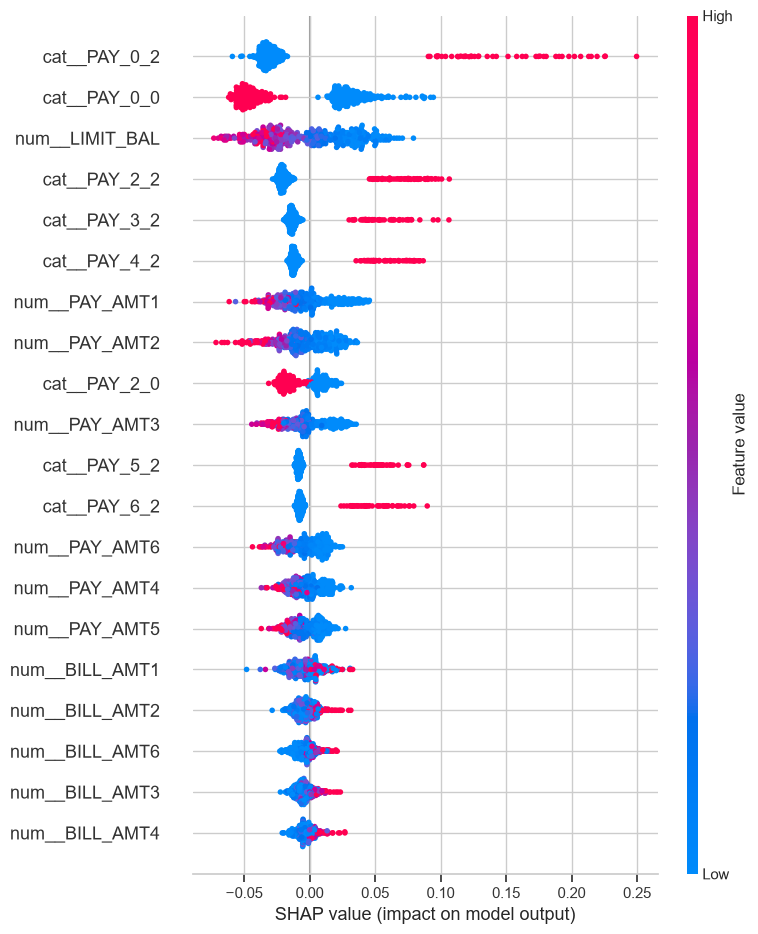

In [27]:
shap.summary_plot(
    shap_values_default,
    X_shap_sample,
    feature_names=feature_names,
    max_display=20
)

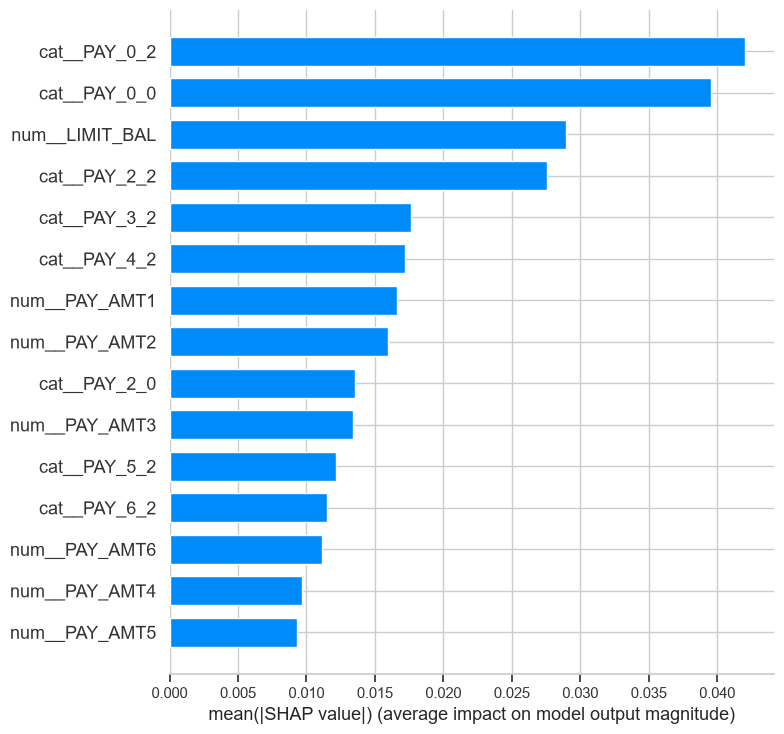

In [28]:
shap.summary_plot(
    shap_values_default,
    X_shap_sample,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15
)

In [29]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train_transformed
        if "X_train_transformed" in globals()
        else final_preprocessor.transform(X_train),
    feature_names=feature_names,
    class_names=["Non-defaulter", "Defaulter"],
    mode="classification",
    discretize_continuous=True,
    random_state=RANDOM_STATE
)

print("LIME explainer initialized successfully.")

LIME explainer initialized successfully.


In [30]:
# Get predictions using the locked Random Forest threshold
rf_test_scores = final_rf_model.predict_proba(X_test_transformed)[:, 1]

rf_test_predictions = (
    rf_test_scores >= selected_thresholds["Random Forest"]
).astype(int)

# Find correctly identified defaulters (True Positives)
true_positive_indices = np.where(
    (y_test.to_numpy() == 1) & (rf_test_predictions == 1)
)[0]

# Select the first correctly identified defaulter
instance_index = true_positive_indices[0]
instance = X_test_transformed[instance_index]

# Generate LIME explanation
lime_exp = lime_explainer.explain_instance(
    data_row=instance,
    predict_fn=final_rf_model.predict_proba,
    num_features=15,
    labels=[1]
)

print("Test record index:", instance_index)
print("Actual class:", y_test.iloc[instance_index])
print("Predicted class:", rf_test_predictions[instance_index])
print("Predicted default probability:", round(rf_test_scores[instance_index], 4))

Test record index: 2
Actual class: 1
Predicted class: 1
Predicted default probability: 0.6933


In [31]:
lime_exp.show_in_notebook(show_table=True)

ImportError: cannot import name 'display' from 'IPython.core.display' (D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\IPython\core\display.py)

In [32]:
from IPython.display import display, HTML

display(HTML(lime_exp.as_html()))

In [33]:
lime_exp.save_to_file("random_forest_lime_explanation.html")

print("LIME explanation saved successfully.")

LIME explanation saved successfully.


In [34]:
# Prepare test data for the seven-dimensional fairness audit

fairness_audit_df = sensitive_test.copy().reset_index(drop=True)

fairness_audit_df["Actual"] = y_test.reset_index(drop=True)
fairness_audit_df["Predicted"] = rf_test_predictions
fairness_audit_df["Default_Probability"] = rf_test_scores

print("Fairness audit dataset prepared.")
print("Shape:", fairness_audit_df.shape)

display(fairness_audit_df.head())

Fairness audit dataset prepared.
Shape: (4500, 7)


,SEX,AGE,EDUCATION,MARRIAGE,Actual,Predicted,Default_Probability
0,2,36,2,1,0,0,0.157180
1,2,30,1,2,0,0,0.150100
2,1,27,2,1,1,1,0.693291
3,2,28,1,1,0,0,0.414070
4,2,40,3,2,0,1,0.845605


In [35]:
# Create age groups for fairness analysis
fairness_audit_df["AGE_GROUP"] = pd.cut(
    fairness_audit_df["AGE"],
    bins=[0, 29, 39, 49, 100],
    labels=["Below 30", "30-39", "40-49", "50+"]
)

protected_attributes = [
    "SEX", "AGE_GROUP", "EDUCATION", "MARRIAGE"
]

demographic_parity_results = []

for attribute in protected_attributes:

    group_rates = fairness_audit_df.groupby(
        attribute, observed=True
    )["Predicted"].mean()

    for group, rate in group_rates.items():
        demographic_parity_results.append({
            "Attribute": attribute,
            "Group": group,
            "Positive Prediction Rate": rate,
            "Sample Count": (
                fairness_audit_df[attribute] == group
            ).sum()
        })

demographic_parity_df = pd.DataFrame(
    demographic_parity_results
)

display(demographic_parity_df.round(4))

# Calculate demographic parity difference
dp_summary = demographic_parity_df.groupby(
    "Attribute"
)["Positive Prediction Rate"].agg(
    ["min", "max"]
)

dp_summary["Demographic Parity Difference"] = (
    dp_summary["max"] - dp_summary["min"]
)

print("\nDemographic Parity Difference:")
display(dp_summary.round(4))

,Attribute,Group,Positive Prediction Rate,Sample Count
0,SEX,1,0.2843,1766
1,SEX,2,0.2363,2734
2,AGE_GROUP,Below 30,0.2702,1414
3,AGE_GROUP,30-39,0.2341,1700
4,AGE_GROUP,40-49,0.2533,975
5,AGE_GROUP,50+,0.2944,411
6,EDUCATION,1,0.2215,1580
7,EDUCATION,2,0.2699,2086
8,EDUCATION,3,0.3029,766
9,EDUCATION,4,0.1000,20



Demographic Parity Difference:


,min,max,Demographic Parity Difference
Attribute,,,
AGE_GROUP,0.2341,0.2944,0.0603
EDUCATION,0.0000,0.3029,0.3029
MARRIAGE,0.2493,0.6250,0.3757
SEX,0.2363,0.2843,0.0480


In [36]:
equal_opportunity_results = []

for attribute in protected_attributes:

    for group, group_data in fairness_audit_df.groupby(
        attribute, observed=True
    ):

        actual_defaulters = group_data[
            group_data["Actual"] == 1
        ]

        if len(actual_defaulters) == 0:
            tpr = np.nan
        else:
            tpr = (
                actual_defaulters["Predicted"] == 1
            ).mean()

        equal_opportunity_results.append({
            "Attribute": attribute,
            "Group": group,
            "True Positive Rate": tpr,
            "Defaulter Count": len(actual_defaulters)
        })

equal_opportunity_df = pd.DataFrame(
    equal_opportunity_results
)

display(equal_opportunity_df.round(4))

eo_summary = equal_opportunity_df.groupby(
    "Attribute"
)["True Positive Rate"].agg(["min", "max"])

eo_summary["Equal Opportunity Difference"] = (
    eo_summary["max"] - eo_summary["min"]
)

print("\nEqual Opportunity Difference:")
display(eo_summary.round(4))

,Attribute,Group,True Positive Rate,Defaulter Count
0,SEX,1,0.5781,448
1,SEX,2,0.5985,548
2,AGE_GROUP,Below 30,0.6306,314
3,AGE_GROUP,30-39,0.5523,344
4,AGE_GROUP,40-49,0.5928,221
5,AGE_GROUP,50+,0.5812,117
6,EDUCATION,1,0.5531,320
7,EDUCATION,2,0.6122,477
8,EDUCATION,3,0.5939,197
9,EDUCATION,4,1.0000,1



Equal Opportunity Difference:


,min,max,Equal Opportunity Difference
Attribute,,,
AGE_GROUP,0.5523,0.6306,0.0782
EDUCATION,0.0000,1.0000,1.0000
MARRIAGE,0.5783,0.7778,0.1995
SEX,0.5781,0.5985,0.0204


In [37]:
calibration_results = []

for attribute in protected_attributes:

    for group, group_data in fairness_audit_df.groupby(
        attribute, observed=True
    ):

        avg_predicted = group_data[
            "Default_Probability"
        ].mean()

        actual_default_rate = group_data[
            "Actual"
        ].mean()

        calibration_results.append({
            "Attribute": attribute,
            "Group": group,
            "Sample Count": len(group_data),
            "Average Predicted Risk": avg_predicted,
            "Actual Default Rate": actual_default_rate,
            "Calibration Gap": abs(
                avg_predicted - actual_default_rate
            )
        })

calibration_df = pd.DataFrame(calibration_results)

display(calibration_df.round(4))

,Attribute,Group,Sample Count,Average Predicted Risk,Actual Default Rate,Calibration Gap
0,SEX,1,1766,0.4106,0.2537,0.1570
1,SEX,2,2734,0.3825,0.2004,0.1820
2,AGE_GROUP,Below 30,1414,0.4112,0.2221,0.1891
3,AGE_GROUP,30-39,1700,0.3735,0.2024,0.1711
4,AGE_GROUP,40-49,975,0.3916,0.2267,0.1649
5,AGE_GROUP,50+,411,0.4204,0.2847,0.1357
6,EDUCATION,1,1580,0.3604,0.2025,0.1578
7,EDUCATION,2,2086,0.4107,0.2287,0.1820
8,EDUCATION,3,766,0.4251,0.2572,0.1679
9,EDUCATION,4,20,0.2782,0.0500,0.2282


In [38]:
disparate_impact_results = []

for attribute in protected_attributes:

    group_rates = fairness_audit_df.groupby(
        attribute, observed=True
    )["Predicted"].mean()

    reference_group = group_rates.idxmax()
    reference_rate = group_rates.max()

    for group, rate in group_rates.items():

        disparate_impact = (
            rate / reference_rate
            if reference_rate > 0
            else np.nan
        )

        disparate_impact_results.append({
            "Attribute": attribute,
            "Group": group,
            "Positive Prediction Rate": rate,
            "Reference Group": reference_group,
            "Disparate Impact Ratio": disparate_impact
        })

disparate_impact_df = pd.DataFrame(
    disparate_impact_results
)

display(disparate_impact_df.round(4))

,Attribute,Group,Positive Prediction Rate,Reference Group,Disparate Impact Ratio
0,SEX,1,0.2843,1,1.0000
1,SEX,2,0.2363,1,0.8312
2,AGE_GROUP,Below 30,0.2702,50+,0.9176
3,AGE_GROUP,30-39,0.2341,50+,0.7952
4,AGE_GROUP,40-49,0.2533,50+,0.8605
5,AGE_GROUP,50+,0.2944,50+,1.0000
6,EDUCATION,1,0.2215,3,0.7314
7,EDUCATION,2,0.2699,3,0.8911
8,EDUCATION,3,0.3029,3,1.0000
9,EDUCATION,4,0.1000,3,0.3302


In [39]:
# Create a copy of the test data
X_counterfactual = X_test.copy()

# Flip gender: 1 becomes 2 and 2 becomes 1
X_counterfactual["SEX"] = X_counterfactual["SEX"].map({
    1: 2,
    2: 1
})

# Predict default probabilities for original and gender-flipped data
original_probabilities = final_rf_pipeline.predict_proba(X_test)[:, 1]

counterfactual_probabilities = final_rf_pipeline.predict_proba(
    X_counterfactual
)[:, 1]

# Compare predictions
probability_changes = np.abs(
    original_probabilities - counterfactual_probabilities
)

original_predictions = (
    original_probabilities >= final_thresholds["Random Forest"]
).astype(int)

counterfactual_predictions = (
    counterfactual_probabilities >= final_thresholds["Random Forest"]
).astype(int)

counterfactual_results = pd.DataFrame({
    "Original Probability": original_probabilities,
    "Counterfactual Probability": counterfactual_probabilities,
    "Absolute Probability Change": probability_changes,
    "Original Prediction": original_predictions,
    "Counterfactual Prediction": counterfactual_predictions
})

print("Average absolute probability change:",
      round(probability_changes.mean(), 4))

print("Maximum absolute probability change:",
      round(probability_changes.max(), 4))

print("Prediction changes:",
      (original_predictions != counterfactual_predictions).sum())

print("Percentage of predictions changed:",
      round(
          (original_predictions != counterfactual_predictions).mean() * 100,
          2
      ), "%")

NameError: name 'final_thresholds' is not defined

In [40]:
# Locked Random Forest threshold from validation
rf_threshold = 0.5057

# Create a copy of the test data
X_counterfactual = X_test.copy()

# Flip gender: 1 becomes 2 and 2 becomes 1
X_counterfactual["SEX"] = X_counterfactual["SEX"].map({
    1: 2,
    2: 1
})

# Predict default probabilities
original_probabilities = final_rf_pipeline.predict_proba(X_test)[:, 1]

counterfactual_probabilities = final_rf_pipeline.predict_proba(
    X_counterfactual
)[:, 1]

# Compare probabilities
probability_changes = np.abs(
    original_probabilities - counterfactual_probabilities
)

# Compare predictions using the same locked threshold
original_predictions = (
    original_probabilities >= rf_threshold
).astype(int)

counterfactual_predictions = (
    counterfactual_probabilities >= rf_threshold
).astype(int)

print("Average absolute probability change:",
      round(probability_changes.mean(), 4))

print("Maximum absolute probability change:",
      round(probability_changes.max(), 4))

print("Prediction changes:",
      (original_predictions != counterfactual_predictions).sum())

print("Percentage of predictions changed:",
      round(
          (original_predictions != counterfactual_predictions).mean() * 100,
          2
      ), "%")

Average absolute probability change: 0.0235
Maximum absolute probability change: 0.1802
Prediction changes: 103
Percentage of predictions changed: 2.29 %


In [41]:
# Create gender-age intersection groups
fairness_audit_df["SEX_AGE_GROUP"] = (
    fairness_audit_df["SEX"].astype(str)
    + " × "
    + fairness_audit_df["AGE_GROUP"].astype(str)
)

intersectional_results = (
    fairness_audit_df.groupby("SEX_AGE_GROUP", observed=True)
    .agg(
        Sample_Count=("Predicted", "count"),
        Positive_Prediction_Rate=("Predicted", "mean"),
        Actual_Default_Rate=("Actual", "mean"),
        Average_Predicted_Risk=("Default_Probability", "mean")
    )
    .reset_index()
)

display(intersectional_results.round(4))

# Calculate the overall prediction-rate gap
intersectional_gap = (
    intersectional_results["Positive_Prediction_Rate"].max()
    - intersectional_results["Positive_Prediction_Rate"].min()
)

print("Intersectional demographic parity gap:",
      round(intersectional_gap, 4))

,SEX_AGE_GROUP,Sample_Count,Positive_Prediction_Rate,Actual_Default_Rate,Average_Predicted_Risk
0,1 × 30-39,687,0.2707,0.2460,0.3983
1,1 × 40-49,415,0.2795,0.2602,0.4039
2,1 × 50+,199,0.3417,0.3065,0.4473
3,1 × Below 30,465,0.2839,0.2366,0.4191
4,2 × 30-39,1013,0.2093,0.1728,0.3566
5,2 × 40-49,560,0.2339,0.2018,0.3825
6,2 × 50+,212,0.2500,0.2642,0.3950
7,2 × Below 30,949,0.2634,0.2150,0.4073


Intersectional demographic parity gap: 0.1324


In [42]:
from sklearn.neighbors import NearestNeighbors

# Find 5 nearest neighbours for each test instance
# Use the transformed test features
nn = NearestNeighbors(n_neighbors=6, metric="euclidean")
nn.fit(X_test_transformed)

distances, neighbour_indices = nn.kneighbors(X_test_transformed)

# Exclude each individual themselves (first neighbour)
neighbour_indices = neighbour_indices[:, 1:]
neighbour_predictions = rf_test_predictions[neighbour_indices]

# Calculate average prediction disagreement with neighbours
individual_disagreement = np.mean(
    neighbour_predictions != rf_test_predictions.reshape(-1, 1),
    axis=1
)

print("Average nearest-neighbour prediction disagreement:",
      round(individual_disagreement.mean(), 4))

print("Percentage of individuals with at least one neighbour receiving a different prediction:",
      round((individual_disagreement > 0).mean() * 100, 2), "%")

print("Maximum individual disagreement:",
      round(individual_disagreement.max(), 4))

Average nearest-neighbour prediction disagreement: 0.1176
Percentage of individuals with at least one neighbour receiving a different prediction: 27.27 %
Maximum individual disagreement: 1.0


In [43]:
final_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1 Score",
        "Balanced Accuracy",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Random Forest": [
        0.7844, 0.5113, 0.5894, 0.8399,
        0.5476, 0.7146, 0.7805, 0.5546
    ],
    "XGBoost": [
        0.7636, 0.4744, 0.6325, 0.8008,
        0.5422, 0.7167, 0.7799, 0.5574
    ]
})

display(final_comparison.round(4))

,Metric,Random Forest,XGBoost
0,Accuracy,0.7844,0.7636
1,Precision,0.5113,0.4744
2,Recall,0.5894,0.6325
3,Specificity,0.8399,0.8008
4,F1 Score,0.5476,0.5422
5,Balanced Accuracy,0.7146,0.7167
6,ROC-AUC,0.7805,0.7799
7,PR-AUC,0.5546,0.5574


In [44]:
fairness_summary = pd.DataFrame({
    "Fairness Dimension": [
        "Demographic Parity",
        "Equal Opportunity",
        "Calibration Bias",
        "Disparate Impact",
        "Counterfactual Fairness",
        "Intersectional Bias",
        "Individual Fairness"
    ],
    "Key Result": [
        "Largest group prediction-rate gap: 0.3757 (Marital status)",
        "Gender TPR gap: 0.0204; rare groups show unstable results",
        "Group-level calibration gaps vary from 0.1357 to 0.5641",
        "Lowest DI ratio: 0.0000 (Education category 6; only 8 samples)",
        "Gender flip changed 103 predictions (2.29%)",
        "Gender × age prediction-rate gap: 0.1324",
        "Average nearest-neighbour disagreement: 0.1176"
    ]
})

display(fairness_summary)

,Fairness Dimension,Key Result
0,Demographic Parity,Largest group prediction-rate gap: 0.3757 (Mar...
1,Equal Opportunity,Gender TPR gap: 0.0204; rare groups show unsta...
2,Calibration Bias,Group-level calibration gaps vary from 0.1357 ...
3,Disparate Impact,Lowest DI ratio: 0.0000 (Education category 6;...
4,Counterfactual Fairness,Gender flip changed 103 predictions (2.29%)
5,Intersectional Bias,Gender × age prediction-rate gap: 0.1324
6,Individual Fairness,Average nearest-neighbour disagreement: 0.1176


In [45]:
final_conclusion = """
FINAL PROJECT CONCLUSION — FAIRXAI

The project developed a machine learning-based financial risk assessment
pipeline using the Taiwan Credit Card Default dataset.

Seven classification models were evaluated, followed by experiments
comparing the original class distribution, class weighting and SMOTENC.
Class weighting achieved the strongest average performance among the
three imbalance-handling strategies.

Random Forest was selected as the final model after comparison with
XGBoost on the untouched test set. It achieved 78.44% accuracy,
0.5476 F1-score and 0.7805 ROC-AUC. XGBoost achieved higher recall,
highlighting the trade-off between identifying more defaulters and
reducing false-positive predictions.

The final Random Forest model was explained using SHAP and LIME.
Repayment history emerged as an important factor influencing predictions.

A seven-dimensional fairness audit examined demographic parity,
equal opportunity, calibration, disparate impact, counterfactual
fairness, intersectional bias and individual fairness. The audit
identified differences across several protected groups and some
sensitivity to gender.

Some fairness results were affected by small group sizes and the
limitations of proxy-based measurements. Therefore, the findings
indicate areas requiring further investigation rather than proving
discrimination.

Overall, FairXAI demonstrates that financial risk models should be
evaluated not only on predictive performance, but also on fairness,
transparency and responsible decision-making.
"""

print(final_conclusion)


FINAL PROJECT CONCLUSION — FAIRXAI

The project developed a machine learning-based financial risk assessment
pipeline using the Taiwan Credit Card Default dataset.

Seven classification models were evaluated, followed by experiments
comparing the original class distribution, class weighting and SMOTENC.
Class weighting achieved the strongest average performance among the
three imbalance-handling strategies.

Random Forest was selected as the final model after comparison with
XGBoost on the untouched test set. It achieved 78.44% accuracy,
0.5476 F1-score and 0.7805 ROC-AUC. XGBoost achieved higher recall,
highlighting the trade-off between identifying more defaulters and
reducing false-positive predictions.

The final Random Forest model was explained using SHAP and LIME.
Repayment history emerged as an important factor influencing predictions.

A seven-dimensional fairness audit examined demographic parity,
equal opportunity, calibration, disparate impact, counterfactual
fairness, int

In [47]:
import joblib
import os

# Create models folder in the current working directory
os.makedirs("models", exist_ok=True)

# Save complete preprocessing + Random Forest pipeline
model_path = os.path.abspath("models/fairxai_random_forest.pkl")

joblib.dump(final_rf_pipeline, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)

Model saved successfully!
Saved location: C:\Users\Aryan\models\fairxai_random_forest.pkl


In [48]:
import os

print("Current notebook directory:", os.getcwd())
print("Model file exists:", os.path.exists(
    r"C:\Users\Aryan\models\fairxai_random_forest.pkl"
))

Current notebook directory: C:\Users\Aryan
Model file exists: True


In [49]:
import os
import shutil

# Your GitHub repository path
repo_path = r"D:\TY_Sem1\MLOps\FairXAi"

# Original saved model
source_path = r"C:\Users\Aryan\models\fairxai_random_forest.pkl"

# Create models folder inside repository
models_path = os.path.join(repo_path, "models")
os.makedirs(models_path, exist_ok=True)

# Copy model into repository
destination_path = os.path.join(
    models_path,
    "fairxai_random_forest.pkl"
)

shutil.copy2(source_path, destination_path)

print("Model copied successfully!")
print("Repository model path:", destination_path)
print("File exists:", os.path.exists(destination_path))

Model copied successfully!
Repository model path: D:\TY_Sem1\MLOps\FairXAi\models\fairxai_random_forest.pkl
File exists: True


In [50]:
import json
import os

repo_path = r"D:\TY_Sem1\MLOps\FairXAi"
models_path = os.path.join(repo_path, "models")

model_config = {
    "model_name": "Random Forest",
    "model_file": "fairxai_random_forest.pkl",
    "threshold": 0.5057,
    "positive_class": "Default",
    "negative_class": "Non-default",
    "dataset": "Taiwan Credit Card Default"
}

config_path = os.path.join(models_path, "model_config.json")

with open(config_path, "w") as file:
    json.dump(model_config, file, indent=4)

print("Configuration saved:", config_path)

Configuration saved: D:\TY_Sem1\MLOps\FairXAi\models\model_config.json


In [51]:
import joblib
import numpy as np
import os

model_path = r"D:\TY_Sem1\MLOps\FairXAi\models\fairxai_random_forest.pkl"

loaded_model = joblib.load(model_path)

# Test prediction on existing test data
test_probabilities = loaded_model.predict_proba(X_test.iloc[:5])[:, 1]

test_predictions = (test_probabilities >= 0.5057).astype(int)

print("Model loaded successfully!")
print("Test probabilities:", np.round(test_probabilities, 4))
print("Test predictions:", test_predictions)

Model loaded successfully!
Test probabilities: [0.1572 0.1501 0.6933 0.4141 0.8456]
Test predictions: [0 0 1 0 1]


In [52]:
import os

repo_path = r"D:\TY_Sem1\MLOps\FairXAi"
explanations_path = os.path.join(repo_path, "explanations")

os.makedirs(explanations_path, exist_ok=True)

print("Explanations folder created:", explanations_path)

Explanations folder created: D:\TY_Sem1\MLOps\FairXAi\explanations


In [53]:
import shutil

lime_source = r"C:\Users\Aryan\random_forest_lime_explanation.html"

lime_destination = os.path.join(
    explanations_path,
    "random_forest_lime_explanation.html"
)

shutil.copy2(lime_source, lime_destination)

print("LIME explanation saved:", lime_destination)

LIME explanation saved: D:\TY_Sem1\MLOps\FairXAi\explanations\random_forest_lime_explanation.html


In [54]:
import matplotlib.pyplot as plt

shap_summary_path = os.path.join(
    explanations_path,
    "shap_summary.png"
)

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values_default,
    X_test_transformed[:500],
    feature_names=feature_names,
    show=False
)

plt.savefig(
    shap_summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("SHAP summary plot saved:", shap_summary_path)

SHAP summary plot saved: D:\TY_Sem1\MLOps\FairXAi\explanations\shap_summary.png


In [55]:
shap_importance_path = os.path.join(
    explanations_path,
    "shap_feature_importance.png"
)

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values_default,
    X_test_transformed[:500],
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.savefig(
    shap_importance_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("SHAP feature importance saved:", shap_importance_path)

SHAP feature importance saved: D:\TY_Sem1\MLOps\FairXAi\explanations\shap_feature_importance.png


In [56]:
for folder, _, files in os.walk(repo_path):
    if "models" in folder or "explanations" in folder:
        for file in files:
            print(os.path.join(folder, file))

D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\configs.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\containers.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\images.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\networks.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\nodes.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\plugins.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\resource.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\secrets.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\services.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\swarm.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\volumes.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\__init__.py
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\docker\models\__pycache__\configs.cpython-311.pyc
D:\TY_Sem1\